# Notebook 14 — Checks on the two dimensions, with counting only

Added November 2026 for the CogForum talk. Every analysis here uses the pipeline's existing tables and arithmetic on counts. No language model is called, and nothing upstream is changed. Outputs go to `v4_rebuild/14_dimension_checks/`.

**Part A. Why two numbers and not five.** The pipeline computes six scores per feature and genre: prevalence, distinctiveness, their product (collocation), TF-IDF, Dunning's G² and the composite. This part recomputes, on the current tables, the comparisons the September 2026 audit made: how the scores correlate, whose top-50 list the composite's top-50 resembles, how each score does alone on the meaning check of Notebook 05, and where court-named features fall on each.

**Part B. Held-out prediction.** The two dimensions are two different predictions. Prevalence, P(feature | genre), says what a film of a given genre will contain. Distinctiveness, P(genre | feature), says what genre a film is, given what it contains. The films are split in half at random. Both numbers are computed on one half and each prediction is tested on the other half. This replaces a language model's sense of what is predictable with a test anyone can recompute.

**Part C. Association over time.** Distinctiveness depends on how large the genre is, so when a genre shrinks its features lose distinctiveness even if nothing about them changes. The odds ratio between feature and genre does not depend on the genre's size. This part computes both for a set of signature features in five-year periods.

**Part D. How much of the narrative filter is transparent.** The share of each grammatical type that the Notebook 03b classifier kept, and Part B repeated with no filter at all.

In [1]:
import os, shutil, tempfile, time
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
except Exception:
    pass

_CANDS = [
    Path('/content/drive/MyDrive/DGK Lab/Reasoning Lab/'
         'DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild'),
    Path('/Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/'
         'My Drive/DGK Lab/Reasoning Lab/'
         'DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild'),
    Path.cwd() / 'v4_rebuild',
    Path.cwd().parent / 'v4_rebuild',
]
V4 = next((c for c in _CANDS if c.exists()), None)
assert V4 is not None, 'Could not locate v4_rebuild; set V4 manually.'
OUT = V4 / '14_dimension_checks'
OUT.mkdir(parents=True, exist_ok=True)
TMP = Path(tempfile.mkdtemp())
def read_parquet(p, **kw):
    local = TMP / p.name          # Drive sometimes serves partial parquet files; read a local copy
    shutil.copy(p, local)
    return pd.read_parquet(local, **kw)

SEED = 20260219
MEASURES = {'prevalence': 'rel_freq_in_genre', 'distinctiveness': 'posterior_smoothed',
            'collocation': 'primary_stockiness', 'tfidf': 'tfidf', 'g2': 'dunning_g2_positive',
            'composite': 'ensemble'}
report = []
def out(s=''):
    print(s); report.append(s)
print('V4 =', V4); print('OUT =', OUT)

V4 = /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild
OUT = /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild/14_dimension_checks


## Load the scored table

In [2]:
cls = read_parquet(V4 / '03b_classification' / 'stockiness_long_classified.parquet')
GEN = sorted(cls['genre'].unique())
narr_cells = cls[cls['is_narrative_element']].copy()
print(f'{len(cls):,} cells; {len(narr_cells):,} narrative cells; {len(GEN)} genres')
out('NOTEBOOK 14 — CHECKS ON THE TWO DIMENSIONS (counting only)')
out(f'{len(cls):,} (feature, type, genre) cells; {len(narr_cells):,} narrative')

345,366 cells; 237,516 narrative cells; 17 genres
NOTEBOOK 14 — CHECKS ON THE TWO DIMENSIONS (counting only)
345,366 (feature, type, genre) cells; 237,516 narrative


## Part A1. How the six scores correlate

Spearman rank correlation among story features, computed inside each genre and averaged over the 17 genres.

In [3]:
names = list(MEASURES)
acc = np.zeros((len(names), len(names)))
for g, d in narr_cells.groupby('genre'):
    acc += d[[MEASURES[n] for n in names]].rank().corr().to_numpy()
corr = pd.DataFrame(acc / len(GEN), index=names, columns=names)
corr.to_parquet(OUT / 'measure_correlation.parquet')
out(''); out('A1. MEAN WITHIN-GENRE SPEARMAN CORRELATION (story features)')
out(corr.round(2).to_string())


A1. MEAN WITHIN-GENRE SPEARMAN CORRELATION (story features)
                 prevalence  distinctiveness  collocation  tfidf    g2  composite
prevalence             1.00             0.34         0.91   0.95  0.36       0.61
distinctiveness        0.34             1.00         0.66   0.41  0.85       0.90
collocation            0.91             0.66         1.00   0.91  0.60       0.86
tfidf                  0.95             0.41         0.91   1.00  0.45       0.67
g2                     0.36             0.85         0.60   0.45  1.00       0.81
composite              0.61             0.90         0.86   0.67  0.81       1.00


## Part A2. Whose top 50 does the composite's top 50 resemble?

For each genre, the 50 highest story features on the composite are compared with the 50 highest on each other score. The table gives the mean number shared, out of 50.

In [4]:
K = 50
rows = []
for g, d in narr_cells.groupby('genre'):
    d = d.assign(key=d['element'] + '|' + d['element_type'])
    top = {n: set(d.nlargest(K, MEASURES[n])['key']) for n in names}
    r = {'genre': g}
    for n in names:
        if n != 'composite':
            r[f'composite_and_{n}'] = len(top['composite'] & top[n])
    r['prevalence_and_distinctiveness'] = len(top['prevalence'] & top['distinctiveness'])
    rows.append(r)
overlap = pd.DataFrame(rows)
overlap.to_parquet(OUT / 'top50_overlap.parquet', index=False)
out(''); out(f'A2. MEAN OVERLAP OF TOP-{K} LISTS ACROSS GENRES (out of {K})')
out(overlap.drop(columns='genre').mean().round(1).to_string())


A2. MEAN OVERLAP OF TOP-50 LISTS ACROSS GENRES (out of 50)
composite_and_prevalence          29.4
composite_and_distinctiveness      1.7
composite_and_collocation         42.3
composite_and_tfidf               31.7
composite_and_g2                  31.9
prevalence_and_distinctiveness     0.0


## Part A3. The meaning check of Notebook 05, one score at a time

Notebook 05 asks whether a genre's top 50 features on the composite sit closer in meaning to the genre than other story features do (cosine similarity between the feature's embedding and the genre's centroid). Here the same question is asked with the top 50 chosen by each score in turn. The comparison group is every other story feature, not one random draw of 50, so the numbers are stable and differ slightly from Notebook 05's.

In [5]:
cen = read_parquet(V4 / '05_embeddings' / 'genre_centroids.parquet')
cen = cen[cen['is_narrative_element']]
rows = []
for g in GEN:
    cg = cen[cen['genre'] == g].assign(key=lambda x: x['element'] + '|' + x['element_type']).set_index('key')['cosine_to_centroid']
    d = narr_cells[narr_cells['genre'] == g]
    d = d.assign(key=d['element'] + '|' + d['element_type'])
    for n in names:
        top = set(d.nlargest(K, MEASURES[n])['key'])
        a = cg[cg.index.isin(top)].to_numpy(); b = cg[~cg.index.isin(top)].to_numpy()
        sp = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
        rows.append({'genre': g, 'measure': n, 'n_top': len(a), 'cohens_d': (a.mean() - b.mean()) / sp})
meaning = pd.DataFrame(rows)
meaning.to_parquet(OUT / 'meaning_by_measure.parquet', index=False)
ms = meaning.groupby('measure')['cohens_d'].agg(mean_d='mean', genres_positive=lambda x: int((x > 0).sum())).loc[names]
out(''); out("A3. MEANING CHECK BY SCORE (top 50 vs all other story features; mean Cohen's d over 17 genres)")
out(ms.round(2).to_string())


A3. MEANING CHECK BY SCORE (top 50 vs all other story features; mean Cohen's d over 17 genres)
                 mean_d  genres_positive
measure                                 
prevalence         0.35               17
distinctiveness    1.20               17
collocation        0.61               16
tfidf              0.40               17
g2                 0.83               17
composite          0.66               17


## Part A4. Where court-named features fall on each score

The median within-genre percentile of the court-named story features of Notebook 07b, for each score, using all matches and the exact matches only. The percentile is taken within genre and grammatical type, on the same row Notebook 07b uses.

In [6]:
stk = cls.copy()
for n, c in MEASURES.items():
    stk[f'p_{n}'] = stk.groupby(['genre', 'element_type'])[c].rank(pct=True)
best = stk.sort_values('ensemble').groupby(['element', 'genre']).tail(1).set_index(['element', 'genre'])
M = read_parquet(V4 / '07b_court_validation' / 'matched_judicial_elements.parquet')
M = M[M['is_narrative'] & M['pct'].notna()]
J = M.join(best[[f'p_{n}' for n in names]], on=['match_element', 'gen'])
assert len(J) == 312 and abs(J['p_composite'].median() - 0.935) < 0.002, (len(J), J['p_composite'].median())
court = pd.DataFrame({'all_matches': J[[f'p_{n}' for n in names]].median(),
                      'exact_matches': J[J['match_method'] == 'exact'][[f'p_{n}' for n in names]].median()})
court.index = names
court.to_parquet(OUT / 'court_by_measure.parquet')
out(''); out(f"A4. COURT-NAMED ELEMENTS: MEDIAN PERCENTILE BY SCORE (all n = {len(J)}, exact n = {int((J['match_method'] == 'exact').sum())})")
out(court.round(3).to_string())


A4. COURT-NAMED ELEMENTS: MEDIAN PERCENTILE BY SCORE (all n = 312, exact n = 59)
                 all_matches  exact_matches
prevalence             0.931          0.873
distinctiveness        0.698          0.763
collocation            0.947          0.904
tfidf                  0.940          0.857
g2                     0.858          0.770
composite              0.935          0.831


## Part B. Held-out prediction

**Setup.** Films are split in half at random (seed 20260219). On half A, for every story feature and genre: prevalence = films of the genre with the feature ÷ films of the genre; distinctiveness = (films of the genre with the feature + α·P(genre)) ÷ (films with the feature + α), α = 1. Features in fewer than 5 half-A films are left out.

**Test 1, genre to content.** Take a half-B film of genre g. Rank every feature by its half-A score in g. If the score is a good guide to what such a film contains, the features the film really has should sit near the top of the ranking. The summary is the AUC: the chance that a feature the film has outranks a feature it lacks (0.5 is guessing, 1 is perfect). It is averaged over up to 300 half-B films per genre. A third ranking, the feature's frequency in all half-A films regardless of genre, shows how much knowing the genre adds.

**Test 2, content to genre.** Take a half-B film and average the half-A score for genre g over the features it contains. If the score is a good guide to genre, films that really are of genre g should get higher averages than films that are not. The summary is again the AUC, over all half-B films with at least 3 scored features.

The whole of Part B is repeated with every feature, narrative or not, so the result can be seen without the narrative classifier.

In [7]:
films = read_parquet(V4 / '01c_union' / 'movies_union.parquet')[['union_id', 'genres_canonical', 'year']]
films['genres'] = films['genres_canonical'].map(lambda g: [str(x) for x in list(g)] if g is not None else [])
fid = {u: i for i, u in enumerate(films['union_id'])}
G = np.zeros((len(films), len(GEN)), dtype=np.float32)
for i, gs in enumerate(films['genres']):
    for g in gs:
        if g in GEN:
            G[i, GEN.index(g)] = 1
idx_all = read_parquet(V4 / '02_elements' / 'element_index.parquet').drop_duplicates()
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(films))
A = np.zeros(len(films), bool); A[perm[:len(films) // 2]] = True
B = ~A
N_FILMS_T1, MIN_TRAIN, MIN_ELEMS = 300, 5, 3

def heldout(pairs, label):
    pairs = pairs.reset_index(drop=True).assign(eid=lambda x: x.index)
    ix = idx_all.merge(pairs, on=['element', 'element_type'])
    X = sparse.csr_matrix((np.ones(len(ix), dtype=np.float32), (ix['union_id'].map(fid).to_numpy(), ix['eid'].to_numpy())),
                          shape=(len(films), len(pairs)))
    X.data[:] = 1
    XA, GA = X[A], G[A]
    n_eg = np.asarray(XA.T @ GA); n_e = np.asarray(XA.sum(0)).ravel(); N_g = GA.sum(0)
    prior = N_g / N_g.sum()
    prev = n_eg / N_g
    dist = (n_eg + prior) / (n_e[:, None] + 1.0)
    overall = n_e / A.sum()
    ok = n_e >= MIN_TRAIN
    XB, GB = X[B].tocsr()[:, ok], G[B]
    prev, dist, overall = prev[ok], dist[ok], overall[ok]
    # Test 1: genre -> content
    r1 = []
    pick = np.random.default_rng(SEED + 1)
    for gi, g in enumerate(GEN):
        rows = np.where(GB[:, gi] == 1)[0]
        rows = pick.choice(rows, size=min(N_FILMS_T1, len(rows)), replace=False)
        a = {'prevalence': [], 'distinctiveness': [], 'overall_frequency': []}
        for r in rows:
            y = np.asarray(XB[r].todense()).ravel()
            if y.sum() < MIN_ELEMS:
                continue
            a['prevalence'].append(roc_auc_score(y, prev[:, gi]))
            a['distinctiveness'].append(roc_auc_score(y, dist[:, gi]))
            a['overall_frequency'].append(roc_auc_score(y, overall))
        r1.append({'set': label, 'genre': g, 'n_films': len(a['prevalence']), **{f'auc_{k}': float(np.mean(v)) for k, v in a.items()}})
    # Test 2: content -> genre
    n_el = np.asarray(XB.sum(1)).ravel(); keep = n_el >= MIN_ELEMS
    SD = (XB @ dist) / np.maximum(n_el[:, None], 1); SPV = (XB @ prev) / np.maximum(n_el[:, None], 1)
    r2 = []
    for gi, g in enumerate(GEN):
        y = GB[keep, gi]
        r2.append({'set': label, 'genre': g, 'n_films': int(keep.sum()), 'n_in_genre': int(y.sum()),
                   'auc_distinctiveness': float(roc_auc_score(y, SD[keep, gi])), 'auc_prevalence': float(roc_auc_score(y, SPV[keep, gi]))})
    return pd.DataFrame(r1), pd.DataFrame(r2), int(ok.sum())

t0 = time.time()
narr_pairs = narr_cells[['element', 'element_type']].drop_duplicates()
all_pairs = cls[['element', 'element_type']].drop_duplicates()
c_n, g_n, k_n = heldout(narr_pairs, 'narrative')
c_a, g_a, k_a = heldout(all_pairs, 'all_elements')
content = pd.concat([c_n, c_a], ignore_index=True); genre_pred = pd.concat([g_n, g_a], ignore_index=True)
content.to_parquet(OUT / 'heldout_content.parquet', index=False)
genre_pred.to_parquet(OUT / 'heldout_genre.parquet', index=False)
print(f'done in {time.time() - t0:.0f} s')
out(''); out(f'B. HELD-OUT PREDICTION ({int(A.sum()):,} films to compute the scores, {int(B.sum()):,} to test; {k_n:,} story features, {k_a:,} of all features)')
out('Test 1, genre to content: mean AUC over genres')
out(content.groupby('set')[['auc_prevalence', 'auc_distinctiveness', 'auc_overall_frequency']].mean().round(3).to_string())
out('Test 2, content to genre: mean AUC over genres')
out(genre_pred.groupby('set')[['auc_distinctiveness', 'auc_prevalence']].mean().round(3).to_string())
out('Test 2 by genre (story features)')
out(g_n[['genre', 'n_in_genre', 'auc_distinctiveness', 'auc_prevalence']].round(3).to_string(index=False))
out('Test 1 by genre (story features)')
out(c_n[['genre', 'n_films', 'auc_prevalence', 'auc_distinctiveness', 'auc_overall_frequency']].round(3).to_string(index=False))

done in 66 s

B. HELD-OUT PREDICTION (22,979 films to compute the scores, 22,979 to test; 15,976 story features, 22,727 of all features)
Test 1, genre to content: mean AUC over genres
              auc_prevalence  auc_distinctiveness  auc_overall_frequency
set                                                                     
all_elements           0.908                0.652                  0.902
narrative              0.901                0.656                  0.894
Test 2, content to genre: mean AUC over genres
              auc_distinctiveness  auc_prevalence
set                                              
all_elements                0.868           0.617
narrative                   0.862           0.630
Test 2 by genre (story features)
          genre  n_in_genre  auc_distinctiveness  auc_prevalence
         Action        3929                0.857           0.615
      Adventure        3088                0.843           0.571
      Animation        1372                0.933 

## Part B3. How stable is each number?

The same split gives a reliability check. Both numbers are computed separately on half A and half B, and compared across features inside each genre (Spearman correlation), by how many of the genre's films mention the feature in the full corpus. The human study used only features in at least 20 films of the genre.

In [8]:
pairs = narr_pairs.reset_index(drop=True).assign(eid=lambda x: x.index)
ix = idx_all.merge(pairs, on=['element', 'element_type'])
X = sparse.csr_matrix((np.ones(len(ix), dtype=np.float32), (ix['union_id'].map(fid).to_numpy(), ix['eid'].to_numpy())), shape=(len(films), len(pairs)))
X.data[:] = 1
def half(mask):
    n_eg = np.asarray(X[mask].T @ G[mask]); n_e = np.asarray(X[mask].sum(0)).ravel(); N_g = G[mask].sum(0)
    return n_eg / N_g, (n_eg + N_g / N_g.sum()) / (n_e[:, None] + 1.0)
pA, dA = half(A); pB, dB = half(B)
full = np.asarray(X.T @ G)
bands = [(5, 20, '5 to 19'), (20, 100, '20 to 99'), (100, 10**9, '100 or more')]
rows = []
for lo, hi, lab in bands:
    rp, rd, n = [], [], 0
    for gi in range(len(GEN)):
        m = (full[:, gi] >= lo) & (full[:, gi] < hi)
        if m.sum() >= 30:
            rp.append(spearmanr(pA[m, gi], pB[m, gi])[0]); rd.append(spearmanr(dA[m, gi], dB[m, gi])[0]); n += int(m.sum())
    rows.append({'films_in_genre': lab, 'n_cells': n, 'prevalence': float(np.mean(rp)), 'distinctiveness': float(np.mean(rd)),
                 'prevalence_sd': float(np.std(rp, ddof=1)), 'distinctiveness_sd': float(np.std(rd, ddof=1)), 'n_genres': len(rp)})
rel = pd.DataFrame(rows)
rel.to_parquet(OUT / 'split_half_reliability.parquet', index=False)
out(''); out('B3. SPLIT-HALF RELIABILITY (mean within-genre Spearman between halves)')
out(rel.round(3).to_string(index=False))


B3. SPLIT-HALF RELIABILITY (mean within-genre Spearman between halves)
films_in_genre  n_cells  prevalence  distinctiveness  prevalence_sd  distinctiveness_sd  n_genres
       5 to 19    73532       0.222            0.521          0.018               0.135        17
      20 to 99    32058       0.757            0.803          0.017               0.075        17
   100 or more    10917       0.938            0.934          0.020               0.031        17


## Part C. Association over time

For a feature e and genre g in one five-year period, the four counts are: films of g with e (a), other films with e (b), films of g without e (c), and other films without e (d).

- Prevalence = a ÷ (a + c).
- Distinctiveness = a ÷ (a + b).
- Genre share = (a + c) ÷ all films.
- Odds ratio = (a × d) ÷ (b × c), with 0.5 added to each count. It says how many times larger the odds of the feature are inside the genre than outside it, and it does not change when the genre grows or shrinks relative to the rest. A value of 1 means no association.

Lift (distinctiveness ÷ genre share) is also written out, but it cannot exceed 1 ÷ genre share, so its ceiling moves with the genre's size; the odds ratio has no such ceiling.

In [9]:
bins = read_parquet(V4 / '08_temporal' / 'stockiness_by_bin.parquet',
                    columns=['element', 'element_type', 'genre', 'bin', 'film_count', 'total_film_count', 'N_bg', 'N_bin'])
SIGNATURE = [('sheriff', 'Western'), ('outlaw', 'Western'), ('vampire', 'Horror'), ('ghost', 'Horror'),
             ('detective', 'Crime'), ('gangster', 'Crime'), ('planet', 'Science Fiction'), ('alien', 'Science Fiction'),
             ('wizard', 'Fantasy'), ('witch', 'Fantasy'), ('wedding', 'Comedy'), ('soldier', 'War')]
MIN_BIN_FILMS, MIN_E_FILMS = 30, 5
rows = []
for el, g in SIGNATURE:
    d = bins[(bins['element'] == el) & (bins['genre'] == g) & (bins['element_type'] == 'noun')]
    d = d[(d['N_bg'] >= MIN_BIN_FILMS) & (d['total_film_count'] >= MIN_E_FILMS)].sort_values('bin')
    for r in d.itertuples():
        a = r.film_count; b = r.total_film_count - a; c = r.N_bg - a; dd = r.N_bin - r.N_bg - b
        share = r.N_bg / r.N_bin
        rows.append({'element': el, 'genre': g, 'bin': int(r.bin), 'films_in_genre': int(r.N_bg), 'films_with_element': int(r.total_film_count),
                     'prevalence': a / r.N_bg, 'distinctiveness': a / r.total_film_count, 'genre_share': share,
                     'lift': (a / r.total_film_count) / share, 'odds_ratio': ((a + .5) * (dd + .5)) / ((b + .5) * (c + .5))})
assoc = pd.DataFrame(rows)
assoc.to_parquet(OUT / 'association_over_time.parquet', index=False)
out(''); out(f'C. ASSOCIATION OVER TIME (periods with {MIN_BIN_FILMS}+ films in the genre and {MIN_E_FILMS}+ films with the feature)')
for (el, g), d in assoc.groupby(['element', 'genre'], sort=False):
    early, late = d[d['bin'] < 1970], d[d['bin'] >= 1990]
    if len(early) and len(late):
        out(f"  {el:<10} {g:<16} before 1970 / 1990 on:  distinctiveness {early['distinctiveness'].median():.2f} / {late['distinctiveness'].median():.2f}   "
            f"genre share {early['genre_share'].median():.3f} / {late['genre_share'].median():.3f}   "
            f"odds ratio {early['odds_ratio'].median():.0f} / {late['odds_ratio'].median():.0f}   prevalence {early['prevalence'].median():.3f} / {late['prevalence'].median():.3f}")
assoc[assoc['element'] == 'sheriff'].round(3)


C. ASSOCIATION OVER TIME (periods with 30+ films in the genre and 5+ films with the feature)
  sheriff    Western          before 1970 / 1990 on:  distinctiveness 0.61 / 0.14   genre share 0.067 / 0.010   odds ratio 24 / 17   prevalence 0.197 / 0.163
  outlaw     Western          before 1970 / 1990 on:  distinctiveness 0.80 / 0.39   genre share 0.067 / 0.010   odds ratio 65 / 66   prevalence 0.158 / 0.105
  vampire    Horror           before 1970 / 1990 on:  distinctiveness 0.93 / 0.82   genre share 0.077 / 0.101   odds ratio 131 / 35   prevalence 0.060 / 0.055
  ghost      Horror           before 1970 / 1990 on:  distinctiveness 0.22 / 0.54   genre share 0.052 / 0.101   odds ratio 7 / 12   prevalence 0.043 / 0.126
  detective  Crime            before 1970 / 1990 on:  distinctiveness 0.44 / 0.48   genre share 0.114 / 0.139   odds ratio 6 / 6   prevalence 0.107 / 0.088
  gangster   Crime            before 1970 / 1990 on:  distinctiveness 0.44 / 0.44   genre share 0.114 / 0.139   odds r

,element,genre,bin,films_in_genre,films_with_element,prevalence,distinctiveness,genre_share,lift,odds_ratio
0,sheriff,Western,1930,50,15,0.140,0.467,0.041,11.247,23.276
1,sheriff,Western,1935,91,31,0.209,0.613,0.067,9.214,27.230
2,sheriff,Western,1940,98,42,0.255,0.595,0.065,9.135,27.547
3,sheriff,Western,1945,97,30,0.186,0.600,0.068,8.876,24.695
4,sheriff,Western,1950,188,39,0.133,0.641,0.109,5.875,16.365
5,sheriff,Western,1955,193,64,0.254,0.766,0.108,7.105,34.996
6,sheriff,Western,1960,63,19,0.143,0.474,0.043,10.902,22.868
7,sheriff,Western,1965,113,39,0.212,0.615,0.077,7.967,23.586
8,sheriff,Western,1970,96,46,0.198,0.413,0.060,6.910,13.573
9,sheriff,Western,1975,48,26,0.083,0.154,0.031,4.965,6.649


## Part D. How much of the narrative filter is transparent

The Notebook 03b classifier is a language model. This table shows how far its decisions follow the grammatical type that the parser assigned, which involves no language model.

In [10]:
pairs_all = cls[['element', 'element_type', 'is_narrative_element', 'element_taxonomy']].drop_duplicates(['element', 'element_type'])
by_type = pairs_all.groupby('element_type')['is_narrative_element'].agg(n='size', kept='sum')
by_type['share_kept'] = by_type['kept'] / by_type['n']
by_type = by_type.sort_values('n', ascending=False)
by_type.to_parquet(OUT / 'classifier_by_type.parquet')
ent = pairs_all['element_type'].str.startswith('entity_')
rule = ~ent                                    # the rule: keep everything that is not a named entity
agree = float((rule == pairs_all['is_narrative_element']).mean())
out(''); out('D. NARRATIVE FILTER BY GRAMMATICAL TYPE')
out(by_type.round(3).to_string())
out(f'A rule with no language model ("keep everything that is not a named entity") agrees with the classifier on {agree * 100:.1f}% of {len(pairs_all):,} features.')
out(pairs_all[~ent & ~pairs_all['is_narrative_element']]['element_taxonomy'].value_counts().to_string())

(OUT / 'dimension_checks_report.txt').write_text('\n'.join(report))
print('\nwrote', OUT / 'dimension_checks_report.txt')


D. NARRATIVE FILTER BY GRAMMATICAL TYPE
                        n  kept  share_kept
element_type                               
noun                11989  7662       0.639
chunk                8069  6754       0.837
verb                 3499  2864       0.819
entity_ORG           1736   258       0.149
entity_GPE           1025    30       0.029
entity_NORP           362   289       0.798
entity_LOC            175    22       0.126
entity_PRODUCT        151    55       0.364
entity_FAC             80    19       0.238
entity_EVENT           65    12       0.185
entity_WORK_OF_ART     61    14       0.230
A rule with no language model ("keep everything that is not a named entity") agrees with the classifier on 74.4% of 27,212 features.
element_taxonomy
generic_or_empty     2814
character_name       2065
place_name            985
proper_noun_other     413

wrote /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Anal

## Figures

The figures below are ordinary matplotlib plots with matplotlib's default look. Each is shown here and saved as a PNG in this notebook's `figures/` folder. The talk's slides use those PNG files as they are.

In [11]:
import matplotlib.pyplot as plt
plt.rcdefaults()                                   # matplotlib's own defaults: white background, boxed axes, DejaVu Sans
plt.rcParams.update({'font.size': 10})            # figures are drawn at the size they have on the slide
BLUE, RED = 'tab:blue', 'tab:red'                  # prevalence is blue, distinctiveness is red, in every figure
FIGDIR = OUT / 'figures'
FIGDIR.mkdir(exist_ok=True)
def wilson(k, n, z=1.96):
    # 95% interval for a proportion k out of n (Wilson score interval)
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n; den = 1 + z * z / n
    mid = (p + z * z / (2 * n)) / den; half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return mid - half, mid + half
def mean_ci(v):
    # 95% interval for a mean, from the spread of the values (t distribution)
    from scipy import stats
    v = np.asarray(v, float); h = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean() - h, v.mean() + h
ERR = dict(ecolor='black', capsize=3, lw=1.2)        # error bars: black, thin, small caps
def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGDIR / f'{name}.png', dpi=200, facecolor='white', bbox_inches='tight')
    plt.show()

### Part A1: how similarly the five scores rank features

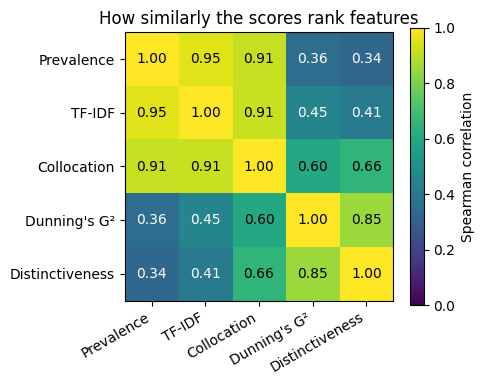

In [12]:
order = ['prevalence', 'tfidf', 'collocation', 'g2', 'distinctiveness']
lab = {'prevalence': 'Prevalence', 'tfidf': 'TF-IDF', 'collocation': 'Collocation', 'g2': "Dunning's G²", 'distinctiveness': 'Distinctiveness', 'composite': 'Composite'}
m = corr.loc[order, order].values
fig, ax = plt.subplots(figsize=(4.9, 4.0))
im = ax.imshow(m, vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{m[i, j]:.2f}', ha='center', va='center', color='black' if m[i, j] > 0.6 else 'white')
ax.set_xticks(range(5)); ax.set_xticklabels([lab[o] for o in order], rotation=30, ha='right')
ax.set_yticks(range(5)); ax.set_yticklabels([lab[o] for o in order])
fig.colorbar(im, ax=ax, label='Spearman correlation')
ax.set_title('How similarly the scores rank features')
save(fig, 'score_correlation')

### Part A2: whose top 50 is the composite's top 50?

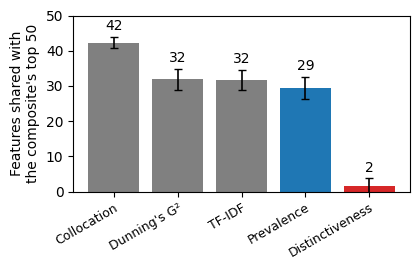

In [13]:
ov = overlap.drop(columns='genre').mean()
keys = ['collocation', 'g2', 'tfidf', 'prevalence', 'distinctiveness']
fig, ax = plt.subplots(figsize=(4.3, 2.8))
ax.bar([lab[k] for k in keys], [ov[f'composite_and_{k}'] for k in keys],
       color=[RED if k == 'distinctiveness' else BLUE if k == 'prevalence' else 'gray' for k in keys])
for i, k in enumerate(keys):
    lo_, hi_ = mean_ci(overlap[f'composite_and_{k}'])
    ax.errorbar(i, ov[f'composite_and_{k}'], yerr=[[ov[f'composite_and_{k}'] - lo_], [hi_ - ov[f'composite_and_{k}']]], fmt='none', **ERR)
    ax.text(i, hi_ + 1.0, f"{ov[f'composite_and_{k}']:.0f}", ha='center', va='bottom')
ax.set_ylim(0, 50); ax.set_ylabel("Features shared with\nthe composite's top 50")
plt.setp(ax.get_xticklabels(), rotation=30, ha='right', rotation_mode='anchor', fontsize=9)
save(fig, 'top50_overlap')

### Part A3: the meaning check, by score

Each bar is the mean over the 17 genres of Cohen's d (how much closer in meaning to the genre the top 50 features are than the other story features), with the top 50 chosen by that score. Each dot is one genre, and the black line is a 95% interval for the mean across genres.

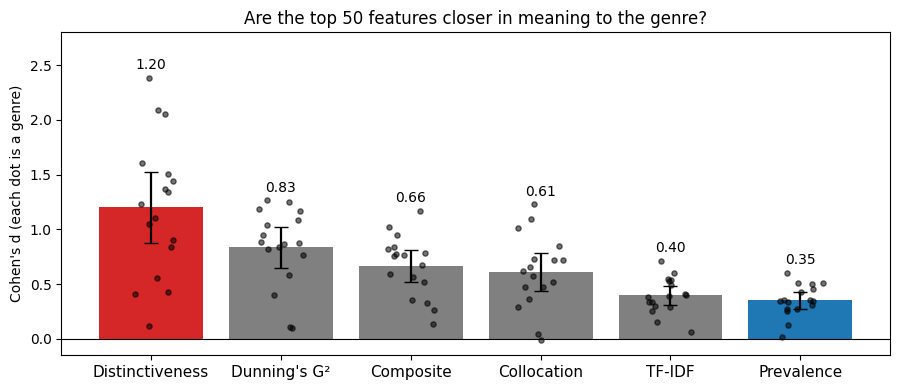

measure          distinctiveness    g2  composite  collocation  tfidf  prevalence
genre                                                                            
Action                      1.34  0.88       0.59         0.52   0.40        0.34
Adventure                   0.56  0.40       0.33         0.37   0.30        0.25
Animation                   1.23  1.19       0.82         0.72   0.54        0.51
Comedy                      0.42  0.10       0.27         0.04   0.15        0.12
Crime                       1.50  1.26       0.76         0.66   0.34        0.27
Drama                       0.12  0.58       0.35         0.29   0.26        0.27
Family                      0.90  0.84       0.76         0.47   0.53        0.51
Fantasy                     1.37  1.04       0.84         0.62   0.41        0.35
History                     0.41  0.11       0.13        -0.01   0.07        0.01
Horror                      2.38  1.16       1.02         1.01   0.60        0.46
Music           

In [14]:
sorder = ['distinctiveness', 'g2', 'composite', 'collocation', 'tfidf', 'prevalence']
piv = meaning.pivot(index='genre', columns='measure', values='cohens_d')[sorder]
fig, ax = plt.subplots(figsize=(9.1, 4.0))
x = np.arange(len(sorder))
ax.bar(x, piv.mean().values, color=[RED if k == 'distinctiveness' else BLUE if k == 'prevalence' else 'gray' for k in sorder])
ci = np.array([mean_ci(piv[k]) for k in sorder])
ax.errorbar(x, piv.mean().values, yerr=[piv.mean().values - ci[:, 0], ci[:, 1] - piv.mean().values], fmt='none', zorder=4, **{**ERR, 'capsize': 5, 'lw': 1.6})
jit = np.random.default_rng(SEED)
for i, k in enumerate(sorder):
    ax.scatter(i + jit.uniform(-0.18, 0.18, len(piv)), piv[k].values, s=14, color='black', alpha=0.55, zorder=3)
    ax.text(i, piv[k].max() + 0.08, f'{piv[k].mean():.2f}', ha='center')
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([lab[k] for k in sorder], fontsize=11); ax.set_ylim(-0.15, 2.8)
ax.set_ylabel("Cohen's d (each dot is a genre)")
ax.set_title('Are the top 50 features closer in meaning to the genre?')
save(fig, 'meaning_by_score')
print(piv.round(2).to_string())

### Part B: held-out prediction

Two tasks, two scores. Each bar is the mean AUC over the 17 genres on the held-out half of the films; each dot is one genre; the black line is a 95% interval for the mean across genres; the dashed line is guessing.

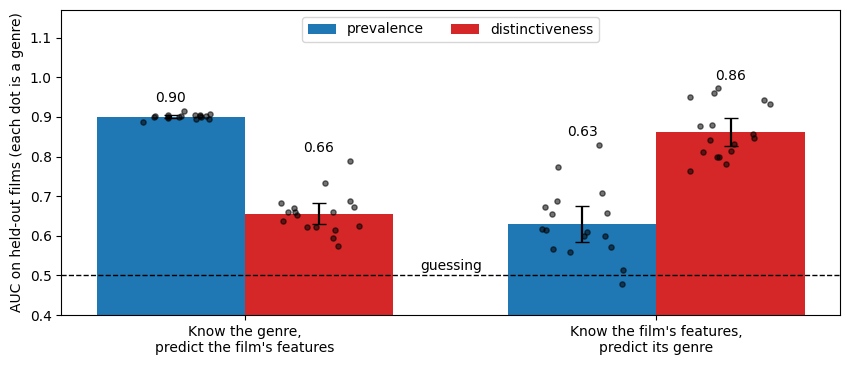

In [15]:
hc_, hg_ = c_n.set_index('genre'), g_n.set_index('genre')
tasks = [("Know the genre,\npredict the film's features", hc_), ("Know the film's features,\npredict its genre", hg_)]
fig, ax = plt.subplots(figsize=(8.6, 3.75))
w = 0.36; jit = np.random.default_rng(SEED)
for t, (name, tab) in enumerate(tasks):
    for off, col, colname, lbl in [(-w / 2, BLUE, 'auc_prevalence', 'prevalence'), (w / 2, RED, 'auc_distinctiveness', 'distinctiveness')]:
        v = tab[colname].values
        ax.bar(t + off, v.mean(), w, color=col, label=lbl if t == 0 else None)
        lo_, hi_ = mean_ci(v)
        ax.errorbar(t + off, v.mean(), yerr=[[v.mean() - lo_], [hi_ - v.mean()]], fmt='none', zorder=4, **{**ERR, 'capsize': 5, 'lw': 1.6})
        ax.scatter(t + off + jit.uniform(-0.1, 0.1, len(v)), v, s=14, color='black', alpha=0.55, zorder=3)
        ax.text(t + off, v.max() + 0.015, f'{v.mean():.2f}', ha='center', va='bottom')
ax.axhline(0.5, color='black', ls='--', lw=1); ax.text(0.5, 0.505, 'guessing', ha='center', va='bottom', fontsize=10)
ax.set_xticks([0, 1]); ax.set_xticklabels([n for n, _ in tasks]); ax.set_ylim(0.4, 1.17)
ax.set_ylabel('AUC on held-out films (each dot is a genre)')
ax.legend(loc='upper center', ncol=2)
save(fig, 'heldout_prediction')

### Part B, genre by genre

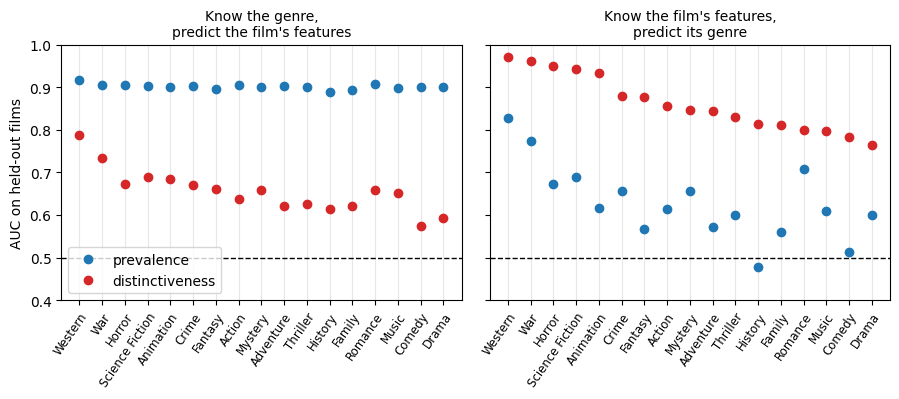

In [16]:
gorder = hg_['auc_distinctiveness'].sort_values(ascending=False).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(9.1, 4.1), sharey=True)
xx = np.arange(len(gorder))
for ax, (name, tab) in zip(axes, tasks):
    ax.plot(xx, tab.loc[gorder, 'auc_prevalence'], 'o', color=BLUE, label='prevalence')
    ax.plot(xx, tab.loc[gorder, 'auc_distinctiveness'], 'o', color=RED, label='distinctiveness')
    ax.axhline(0.5, color='black', ls='--', lw=1); ax.set_ylim(0.4, 1.0); ax.set_title(name, fontsize=10); ax.grid(axis='x', alpha=0.3)
    ax.set_xticks(xx); ax.set_xticklabels(gorder, rotation=55, ha='right', rotation_mode='anchor', fontsize=8.5)
axes[0].set_ylabel('AUC on held-out films'); axes[0].legend(loc='lower left')
save(fig, 'heldout_by_genre')

### Part B3: how stable each number is

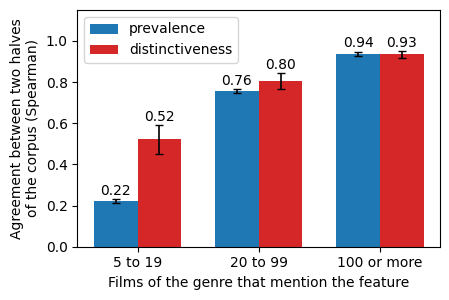

In [17]:
fig, ax = plt.subplots(figsize=(4.6, 3.1))
x = np.arange(len(rel)); w = 0.36
from scipy import stats as _st
half = lambda sd: _st.t.ppf(0.975, rel['n_genres'] - 1) * sd / np.sqrt(rel['n_genres'])     # 95% interval across genres
ax.bar(x - w / 2, rel['prevalence'], w, color=BLUE, label='prevalence', yerr=half(rel['prevalence_sd']), error_kw=ERR)
ax.bar(x + w / 2, rel['distinctiveness'], w, color=RED, label='distinctiveness', yerr=half(rel['distinctiveness_sd']), error_kw=ERR)
for xi, (pv_, dv_, ph_, dh_) in enumerate(zip(rel['prevalence'], rel['distinctiveness'], half(rel['prevalence_sd']), half(rel['distinctiveness_sd']))):
    ax.text(xi - w / 2, pv_ + ph_ + 0.02, f'{pv_:.2f}', ha='center'); ax.text(xi + w / 2, dv_ + dh_ + 0.02, f'{dv_:.2f}', ha='center')
ax.set_xticks(x); ax.set_xticklabels(rel['films_in_genre']); ax.set_ylim(0, 1.15)
ax.set_xlabel('Films of the genre that mention the feature'); ax.set_ylabel('Agreement between two halves\nof the corpus (Spearman)')
ax.legend(loc='upper left')
save(fig, 'split_half_reliability')

### Part C: features over time, three genres at a time

By five-year period: prevalence, distinctiveness, and the genre's share of all films. The second line of each title gives the odds ratio between feature and genre before 1970, then from 1990 on.

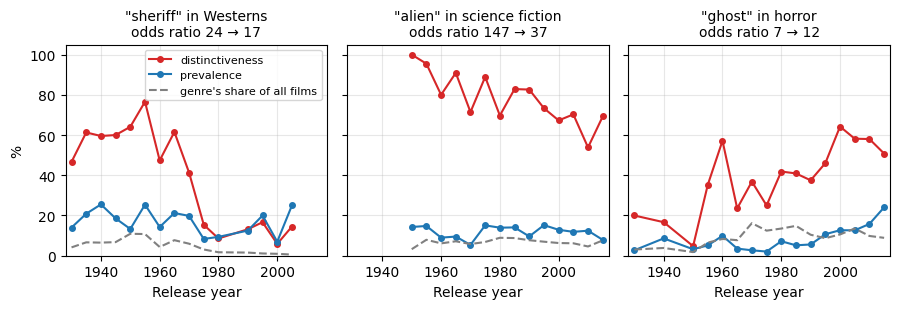

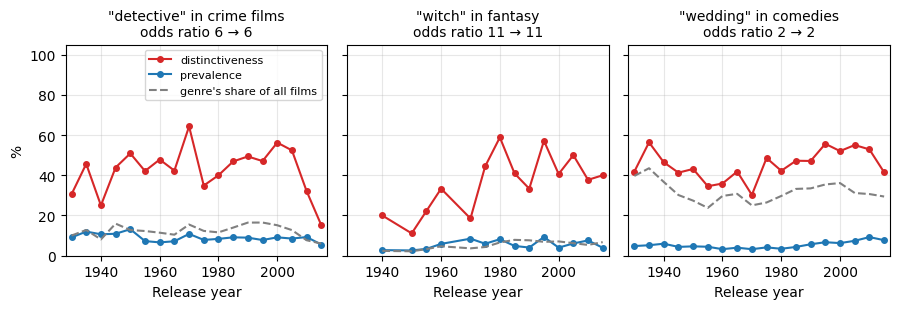

In [18]:
SHORT = {'Western': 'Westerns', 'Horror': 'horror', 'Crime': 'crime films', 'Science Fiction': 'science fiction', 'Fantasy': 'fantasy', 'Comedy': 'comedies'}
def over_time(panels, name):
    fig, axes = plt.subplots(1, 3, figsize=(9.1, 3.2), sharey=True)
    for ax, (el, g) in zip(axes, panels):
        d = assoc[(assoc['element'] == el) & (assoc['genre'] == g) & (assoc['bin'] >= 1930)].sort_values('bin')
        ax.plot(d['bin'], 100 * d['distinctiveness'], 'o-', ms=4, color=RED, label='distinctiveness')
        ax.plot(d['bin'], 100 * d['prevalence'], 'o-', ms=4, color=BLUE, label='prevalence')
        ax.plot(d['bin'], 100 * d['genre_share'], '--', color='gray', label="genre's share of all films")
        e, l = d[d['bin'] < 1970]['odds_ratio'].median(), d[d['bin'] >= 1990]['odds_ratio'].median()
        ax.set_title(f'"{el}" in {SHORT[g]}\nodds ratio {e:.0f} → {l:.0f}', fontsize=10)
        ax.set_xlabel('Release year'); ax.set_ylim(0, 105); ax.set_xlim(1928, 2017); ax.grid(alpha=0.3)
    axes[0].set_ylabel('%'); axes[0].legend(loc='upper right', fontsize=8)
    save(fig, name)
over_time([('sheriff', 'Western'), ('alien', 'Science Fiction'), ('ghost', 'Horror')], 'over_time_three')
over_time([('detective', 'Crime'), ('witch', 'Fantasy'), ('wedding', 'Comedy')], 'over_time_three_more')

### Part C: the tie between feature and genre, net of the genre's size

Distinctiveness falls when a genre shrinks even if nothing about the feature changes. The odds ratio does not: it compares the odds of the feature inside the genre with the odds outside it. This plot shows the odds ratio itself, period by period, for the three features of the first figure. A value of 1 would mean no tie between feature and genre. The scale is logarithmic.

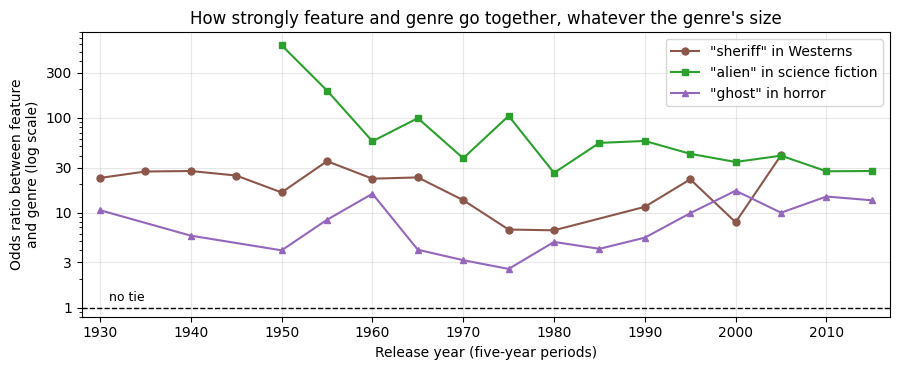

In [19]:
fig, ax = plt.subplots(figsize=(9.1, 3.8))
for (el, g), col, mk in [(('sheriff', 'Western'), 'tab:brown', 'o'), (('alien', 'Science Fiction'), 'tab:green', 's'), (('ghost', 'Horror'), 'tab:purple', '^')]:
    d = assoc[(assoc['element'] == el) & (assoc['genre'] == g) & (assoc['bin'] >= 1930)].sort_values('bin')
    ax.plot(d['bin'], d['odds_ratio'], marker=mk, ms=5, color=col, label=f'"{el}" in {SHORT[g]}')
ax.set_yscale('log'); ax.set_yticks([1, 3, 10, 30, 100, 300]); ax.set_yticklabels(['1', '3', '10', '30', '100', '300'])
ax.axhline(1, color='black', ls='--', lw=1); ax.text(1931, 1.08, 'no tie', fontsize=9, va='bottom')
ax.set_xlim(1928, 2017); ax.set_ylim(0.8, 800); ax.grid(alpha=0.3)
ax.set_xlabel('Release year (five-year periods)'); ax.set_ylabel('Odds ratio between feature\nand genre (log scale)')
ax.set_title("How strongly feature and genre go together, whatever the genre's size")
ax.legend(loc='upper right')
save(fig, 'odds_ratio_over_time')

## Outputs

In `v4_rebuild/14_dimension_checks/`: `measure_correlation.parquet`, `top50_overlap.parquet`, `meaning_by_measure.parquet`, `court_by_measure.parquet`, `heldout_content.parquet`, `heldout_genre.parquet`, `split_half_reliability.parquet`, `association_over_time.parquet`, `classifier_by_type.parquet`, `dimension_checks_report.txt`, and the figures in `figures/`.